# VOC12 dataset segmentation*

JPEG images: [link](https://drive.google.com/file/d/1MTgdBUwwBljzHIGz3bIqdLfu4qPx-PuP/view)

Ground truth labels: [link](https://drive.google.com/file/d/1lR-Ihrg7yE0YVS9PxZTW-_XT6C8rZEnc/view)

Propose a simple method for object segmentation. Pick 1-2 images from the provided dataset. You may use one or multiple segmentation methods such as:

- grabcut
- superpixel segmentation
- floodfill
- thresholding
- and so on ...

Use provided ground truth label to compute Dice Score with your prediction (you may choose only 1 specific object for segmentation in case of multiple objects presented in the image)

This part of segmentation using standard methods is optional for VOC12


In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
image_dir = 'images/voc-data'
label_dir = 'images/voc-labels'

image_files = list(map(lambda f: os.path.join(image_dir, f), os.listdir(image_dir)))
label_files = list(map(lambda f: os.path.join(label_dir, f), os.listdir(label_dir)))

file1, file1_label = image_files[0], label_files[0]
file2, file2_label = image_files[1], label_files[1]

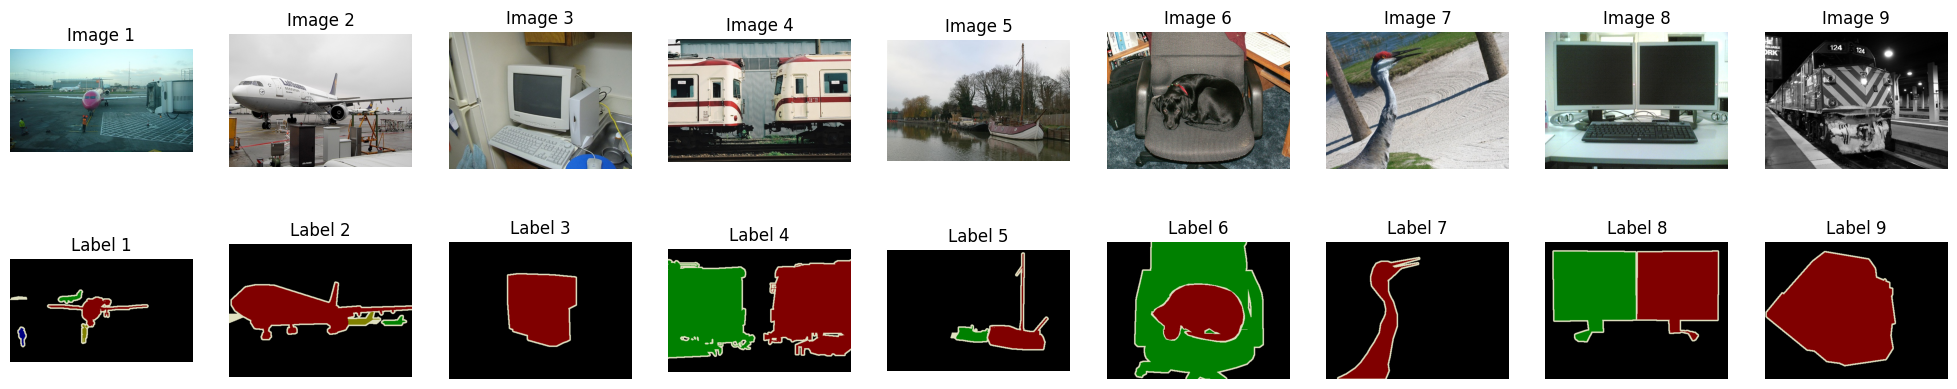

In [3]:
# Plot 9 the images with labels under the same figure
fig, axs = plt.subplots(2, 9, figsize=(25, 5))
for i in range(9):
    img = cv.imread(image_files[i])
    axs[0, i].imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    axs[0, i].axis('off')
    axs[0, i].set_title('Image {}'.format(i + 1))

    label = cv.imread(label_files[i])
    axs[1, i].imshow(cv.cvtColor(label, cv.COLOR_BGR2RGB))
    axs[1, i].axis('off')
    axs[1, i].set_title('Label {}'.format(i + 1))

plt.show()

## Dice score

In [4]:
def dice_score(img1, img2, segment_color=None):
    assert img1.shape == img2.shape, 'Image shapes do not match'

    # Get the segment with the specified color
    if segment_color is not None:
        img1 = (img1 == segment_color).astype(np.uint8)
        img2 = (img2 == segment_color).astype(np.uint8)

    # Convert to binary
    img1 = (img1 > 0).astype(np.uint8)
    img2 = (img2 > 0).astype(np.uint8)

    # Compute the dice score
    intersection = np.sum(img1 * img2)
    return 2 * intersection / (np.sum(img1) + np.sum(img2))

Number of segments: 5
Colors of segments:
[[  0   0   0]
 [  0   0 128]
 [  0 128   0]
 [  0 128 128]
 [192 224 224]]
Dice score between different segments: 0.7112
Dice score between the same segments: 1.0000


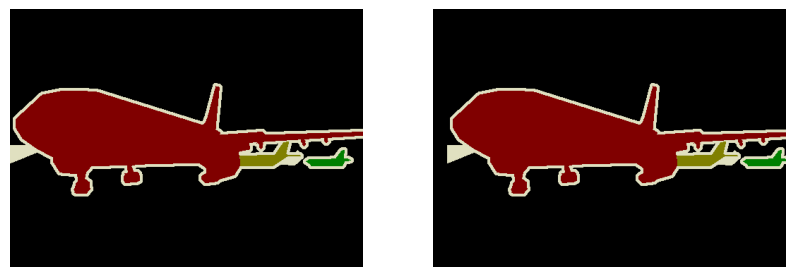

In [5]:
lbl1 = cv.imread(file2_label)

# shift pixels to the right
shift = 20
lbl2 = np.zeros_like(lbl1)
lbl2[:, shift:, :] = lbl1[:, :-shift, :]

segment_colors = np.unique(lbl1.reshape(-1, lbl1.shape[2]), axis=0)
print(f'Number of segments: {len(segment_colors)}')
print(f'Colors of segments:\n{segment_colors}')
print(f'Dice score between different segments: {dice_score(lbl1, lbl2):.4f}')
print(f'Dice score between the same segments: {dice_score(lbl1, lbl1):.4f}')

# plot the images
plt.subplots(1, 2, figsize=(10, 5))
plt.subplot(121)
plt.imshow(cv.cvtColor(lbl1, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.subplot(122)
plt.imshow(cv.cvtColor(lbl2, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## Superpixel segmentation

Number of superpixels: 70


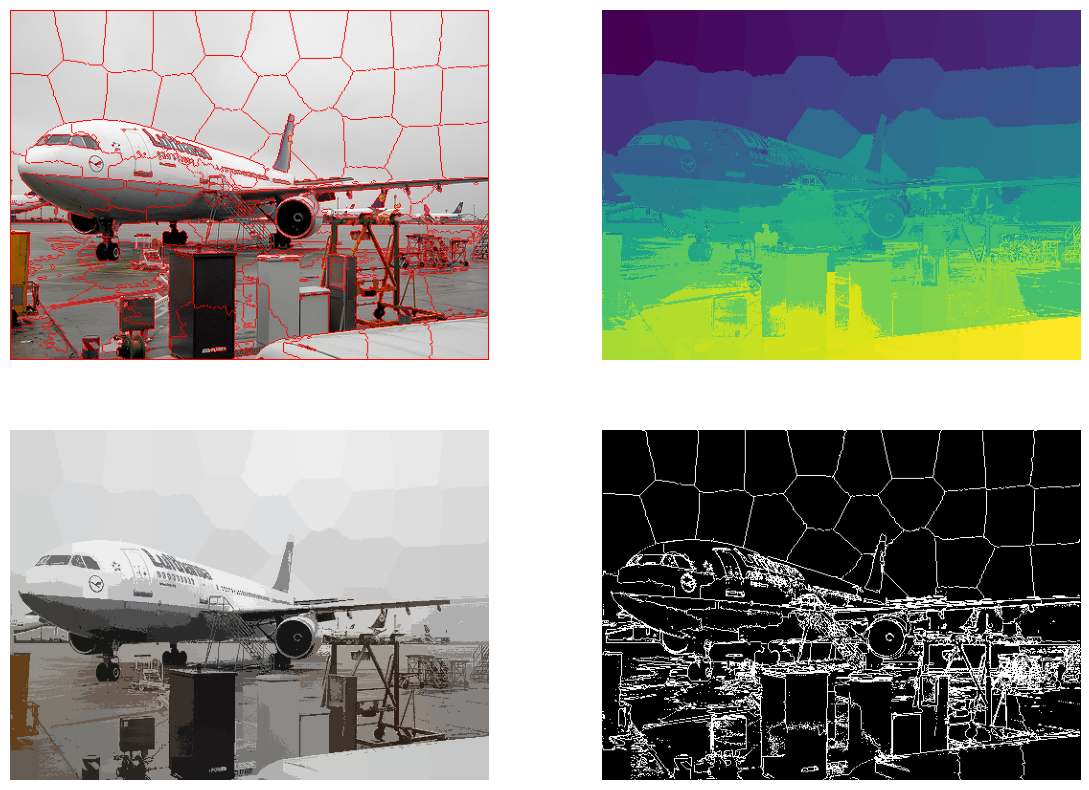

In [177]:
# read image
img = cv.imread(file2)
lab = cv.cvtColor(img, cv.COLOR_BGR2LAB)

# set up parameters
region_size = 50
ruler = 20.0

# apply superpixel segmentation
slic = cv.ximgproc.createSuperpixelSLIC(
    lab, cv.ximgproc.SLIC, region_size, ruler
)

slic.iterate(10)

# retrieve the segmentation result
labels = slic.getLabels()
contour_mask = slic.getLabelContourMask(False)
num_superpixels = slic.getNumberOfSuperpixels()
print(f'Number of superpixels: {num_superpixels}')

for label in np.unique(labels):
    mask = np.argwhere(label == labels)
    x, y = mask[:, 0], mask[:, 1]
    avg_color = np.mean(lab[x, y, :], axis=0)
    lab[x, y, :] = avg_color

superpixel_img = cv.cvtColor(lab, cv.COLOR_LAB2BGR)

# Apply watershed segmentation
markers = slic.getLabels()
markers = markers + 1
markers[contour_mask == 255] = 0
markers = cv.watershed(img, markers)

result = img.copy()
result[markers == -1] = [0, 0, 255]

# Visualize the superpixel segmentation
plt.subplots(2, 2, figsize=(14, 10))
plt.subplot(221)
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.subplot(222)
plt.imshow(labels)
plt.axis('off')
plt.subplot(223)
plt.imshow(cv.cvtColor(superpixel_img, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.subplot(224)
plt.imshow(cv.cvtColor(contour_mask, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

Number of superpixels: 165


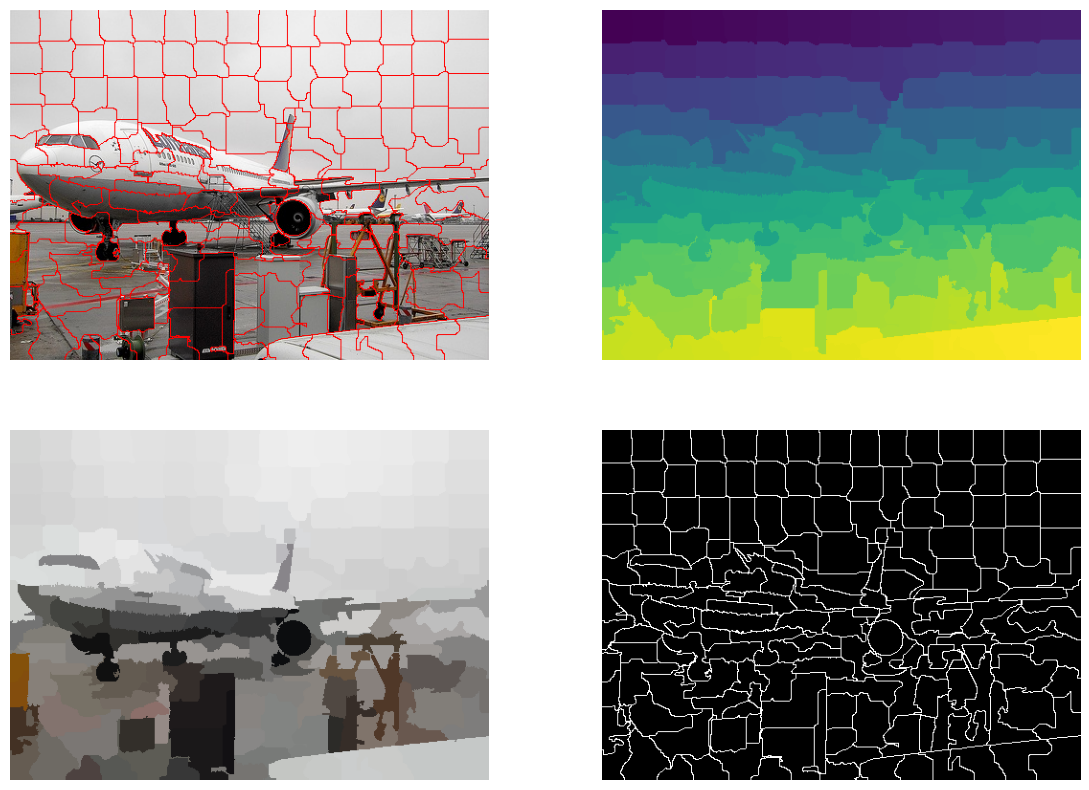

In [180]:
# read image
img = cv.imread(file2)
lab = cv.cvtColor(img, cv.COLOR_BGR2Lab)

# set up parameters
height, width, channels = lab.shape
num_superpixels = 200
num_levels = 4
prior = 2
num_histogram_bins = 5
double_step = False

# apply superpixel segmentation
seeds = cv.ximgproc.createSuperpixelSEEDS(
    width, height, channels, num_superpixels, num_levels, prior, num_histogram_bins, double_step
)

seeds.iterate(lab, 6)

# retrieve the segmentation result
labels = seeds.getLabels()
contour_mask = seeds.getLabelContourMask(False)
num_superpixels = seeds.getNumberOfSuperpixels()
print(f'Number of superpixels: {num_superpixels}')

for label in np.unique(labels):
    mask = np.argwhere(label == labels)
    x, y = mask[:, 0], mask[:, 1]
    avg_color = np.mean(lab[x, y, :], axis=0)
    lab[x, y, :] = avg_color

superpixel_img = cv.cvtColor(lab, cv.COLOR_LAB2BGR)

mask_inv = cv.bitwise_not(contour_mask)

result = img.copy()
result[mask_inv == 0] = [0, 0, 255]

# show output
plt.subplots(2, 2, figsize=(14, 10))
plt.subplot(221)
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.subplot(222)
plt.imshow(labels)
plt.axis("off")
plt.subplot(223)
plt.imshow(cv.cvtColor(superpixel_img, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.subplot(224)
plt.imshow(cv.cvtColor(contour_mask, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## Grabcut

In [45]:
def segment_ventricles(image, user_mask, num_iterations: int = 5):
    mask = np.where(user_mask == FG_COL, cv.GC_FGD, cv.GC_PR_BGD).astype(np.uint8)
    mask[user_mask == PR_FG_COL] = cv.GC_PR_FGD
    mask[user_mask == PR_BG_COL] = cv.GC_PR_BGD
    mask[user_mask == BG_COL] = cv.GC_BGD

    if not np.any(mask == cv.GC_FGD):
        print('No probable foreground found.')
        return

    try:
        bgd_model = np.zeros((1, 65), np.float64)
        fgd_model = np.zeros((1, 65), np.float64)
        cv.grabCut(image, mask, None, bgd_model, fgd_model, num_iterations, cv.GC_INIT_WITH_MASK)
    except cv.error as e:
        print(e)
        return

    mask_ventricles = np.where((mask == cv.GC_PR_BGD) | (mask == cv.GC_BGD), 0, 1).astype('uint8')
    image_segmented = image * mask_ventricles[:, :, np.newaxis]

    return image_segmented


def draw_mask(event, x, y, flags, param):
    global drawing
    if event == cv.EVENT_LBUTTONDOWN:
        drawing = True

    elif event == cv.EVENT_MOUSEMOVE:
        if drawing:
            cv.circle(initial_mask, (x, y), brush_size, brush_color, -1)

    elif event == cv.EVENT_LBUTTONUP:
        drawing = False


def read_image(img_file: str, lbl_file: str, scale: float = 2.0):
    img = cv.imread(img_file, cv.IMREAD_COLOR)
    img = cv.resize(img, (0, 0), fx=scale, fy=scale)
    lbl = cv.imread(lbl_file, cv.IMREAD_COLOR)
    lbl = cv.resize(lbl, (0, 0), fx=scale, fy=scale)
    mask = np.zeros(img.shape[:2], dtype=np.uint8)
    return img, lbl, mask


drawing = False
brush_size = 3
brush_color = 255
img = lbl = initial_mask = None

FG_COL = 255
PR_FG_COL = 254
PR_BG_COL = 253
BG_COL = 252


def interactive_grabcut(img_files: list[str], lbl_files: list[str], scale: float = 2.0):
    global brush_size, brush_color, img, lbl, initial_mask

    idx = 0
    img, lbl, initial_mask = read_image(img_files[idx], lbl_files[idx], scale)
    mask_file = 'mask.png'

    window_name = 'Draw Mask'
    cv.namedWindow(window_name)
    cv.setMouseCallback(window_name, draw_mask)

    print('''
    Controls:
        - Left click and drag to draw mask
        - 'g' perform GrabCut segmentation
        - 'n' and 'p' to go to next/previous image
        - 's' and 'l' to save/load mask
        - 'e' to erase drawn mask
        - 'c' clear the mask
        - '+' and '-' to increase/decrease brush size
        - '0', '1', '2', '3' to change GrabCut mode (0: BGD, 1: FGD, 2: PR_BGD, 3: PR_FGD)
        - 'q' to quit
    ''')

    segmented = None
    while True:
        combined_image = cv.addWeighted(img, 0.7, cv.cvtColor(initial_mask, cv.COLOR_GRAY2BGR), 0.3, 0)
        cv.imshow(window_name, combined_image)

        key = cv.waitKey(1) & 0xFF

        if key == ord('q'):  # Quit
            break
        elif key == ord('g'):  # Perform grabcut segmentation
            segmented = segment_ventricles(img, initial_mask, num_iterations=10)
            if segmented is None:
                continue
            result = np.hstack((lbl, segmented))
            result = cv.resize(result, (0, 0), fx=1 / scale, fy=1 / scale)
            dice = dice_score(lbl, segmented)
            cv.putText(result, f'Dice: {dice:.3f}', (14, 30), cv.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
            cv.imshow('VOC12', result)
            plot_segmentation(segmented)
        elif key == ord('c'):  # Clear the mask
            initial_mask = np.zeros(img.shape[:2], dtype=np.uint8)
        elif key == ord('s'):  # Save the mask
            cv.imwrite(mask_file, initial_mask)
        elif key == ord('l'):  # Load the mask
            try:
                initial_mask = cv.imread(mask_file, cv.IMREAD_GRAYSCALE)
                initial_mask = cv.resize(initial_mask, (0, 0), fx=scale, fy=scale)
            except cv.error as e:
                print(e)
        elif key == ord('+'):  # Increase brush size
            brush_size = min(brush_size + 1, 10)
        elif key == ord('-'):  # Decrease brush size
            brush_size = max(brush_size - 1, 1)
        elif key == ord('n'):  # Next image
            idx = (idx + 1) % len(img_files)
            img, lbl, initial_mask = read_image(img_files[idx], lbl_files[idx], scale)
        elif key == ord('p'):  # Previous image
            idx = (idx - 1) % len(img_files)
            img, lbl, initial_mask = read_image(img_files[idx], lbl_files[idx], scale)
        elif key == ord('e'):  # Erase mode
            brush_color = 255 if brush_color == 0 else 0
        elif key == ord('0'):  # Set background
            brush_color = BG_COL
        elif key == ord('1'):  # Set foreground
            brush_color = FG_COL
        elif key == ord('2'):  # Set probable background
            brush_color = PR_BG_COL
        elif key == ord('3'):  # Set probable foreground
            brush_color = PR_FG_COL

    cv.destroyAllWindows()


def plot_segmentation(segmented):
    if segmented is None:
        return
    fig = plt.figure(figsize=(16, 4))
    fig.suptitle('GrabCut Segmentation', fontsize=16)
    plt.subplot(131), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title('Original'), plt.xticks([]), plt.yticks([])
    plt.subplot(132), plt.imshow(cv.cvtColor(segmented, cv.COLOR_BGR2RGB))
    plt.title('Segmented'), plt.xticks([]), plt.yticks([])
    plt.subplot(133), plt.imshow(cv.cvtColor(lbl, cv.COLOR_BGR2RGB))
    plt.title('Ground Truth'), plt.xticks([]), plt.yticks([])
    plt.tight_layout()
    plt.show()
    print(f'Dice score: {dice_score(lbl, segmented):.3f}')


    Controls:
        - Left click and drag to draw mask
        - 'g' perform GrabCut segmentation
        - 'n' and 'p' to go to next/previous image
        - 's' and 'l' to save/load mask
        - 'e' to erase drawn mask
        - 'c' clear the mask
        - '+' and '-' to increase/decrease brush size
        - '0', '1', '2', '3' to change GrabCut mode (0: BGD, 1: FGD, 2: PR_BGD, 3: PR_FGD)
        - 'q' to quit
    


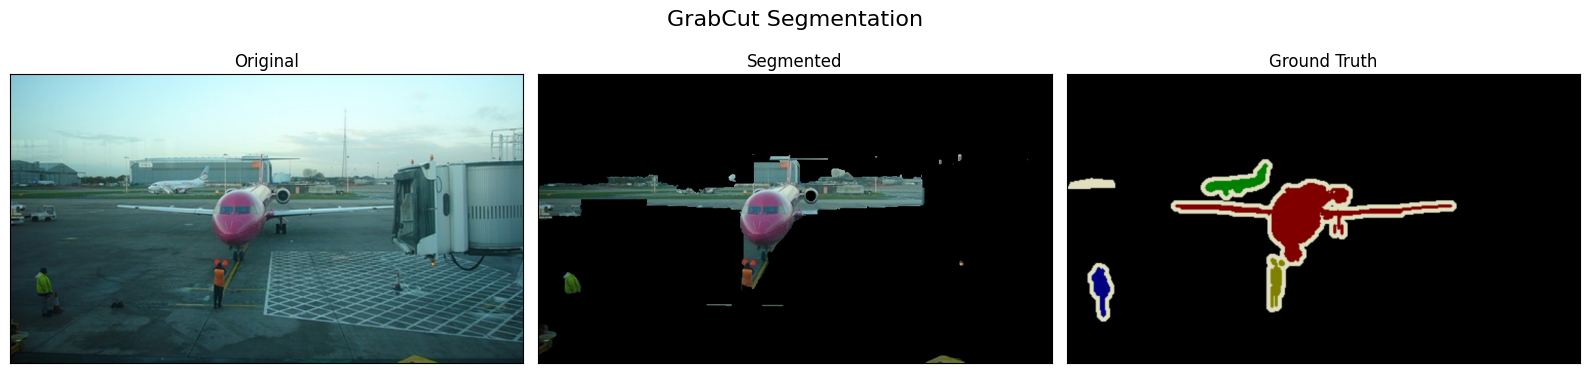

Dice score: 0.375


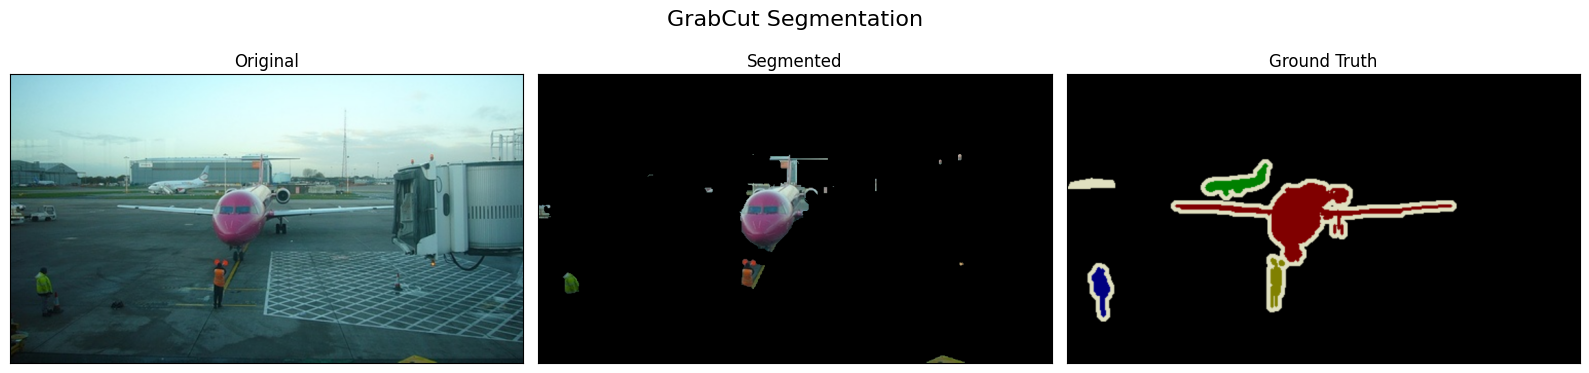

Dice score: 0.284


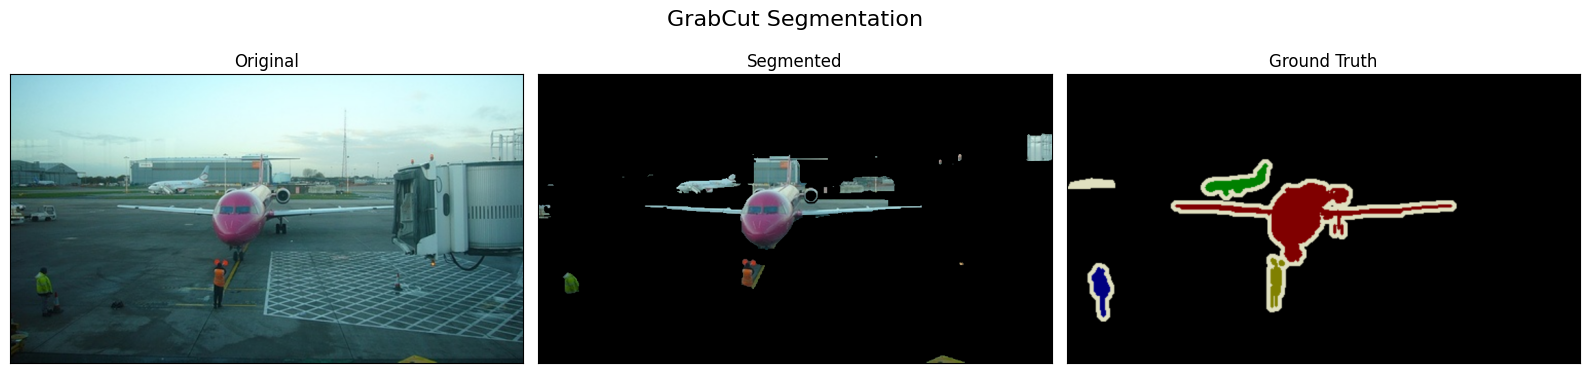

Dice score: 0.343


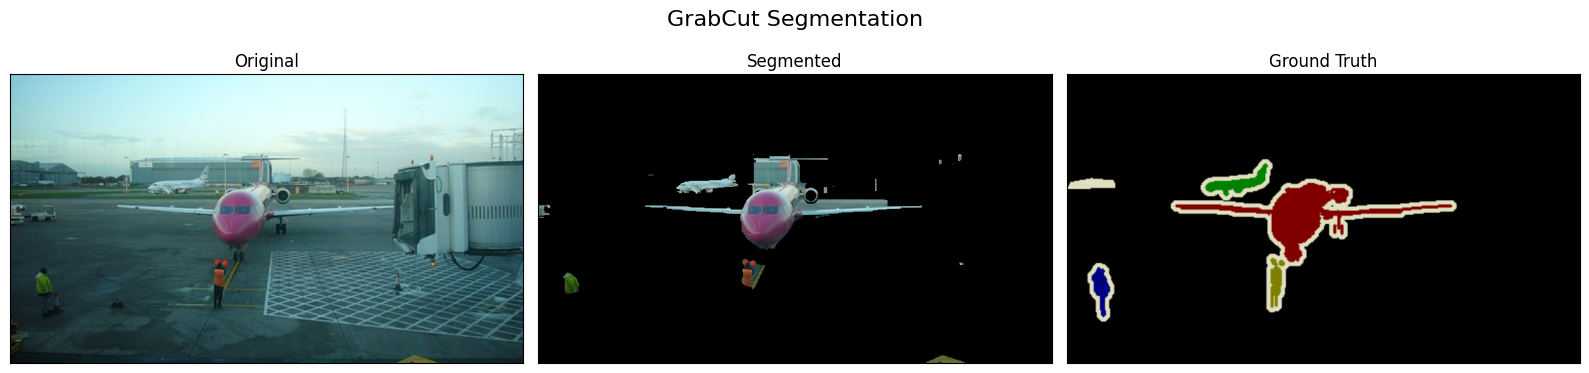

Dice score: 0.369


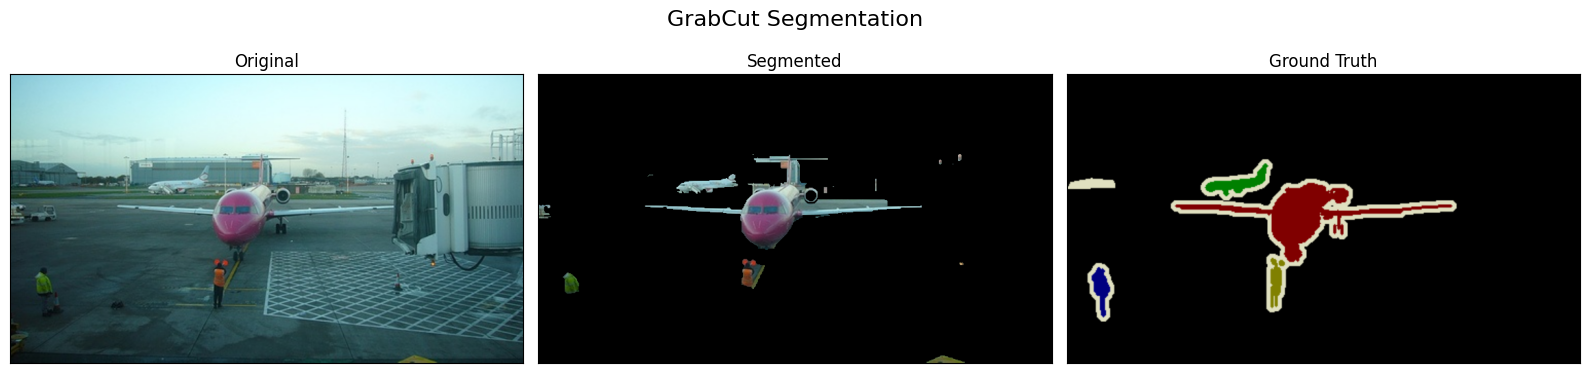

Dice score: 0.371


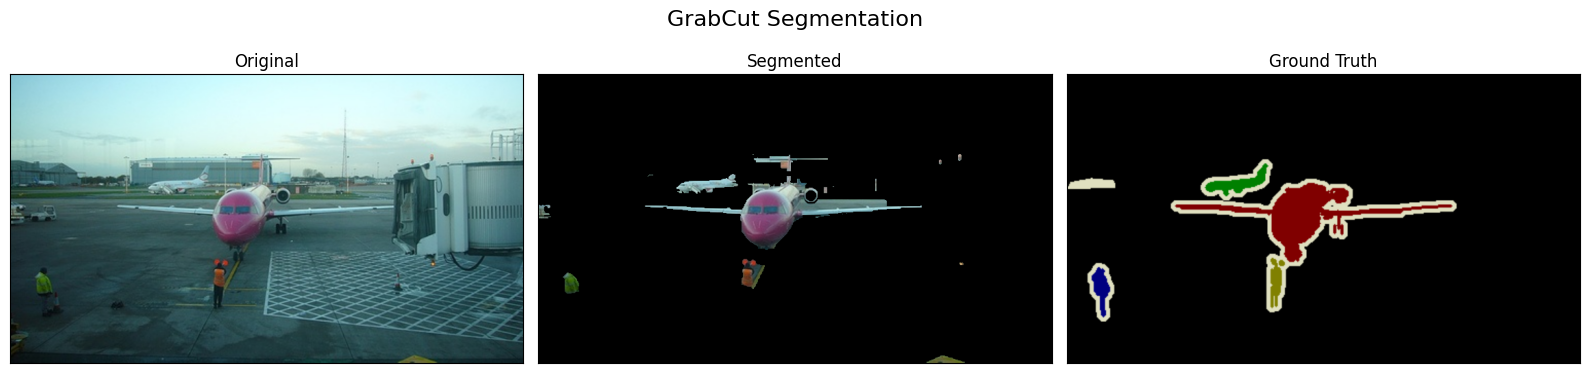

Dice score: 0.374


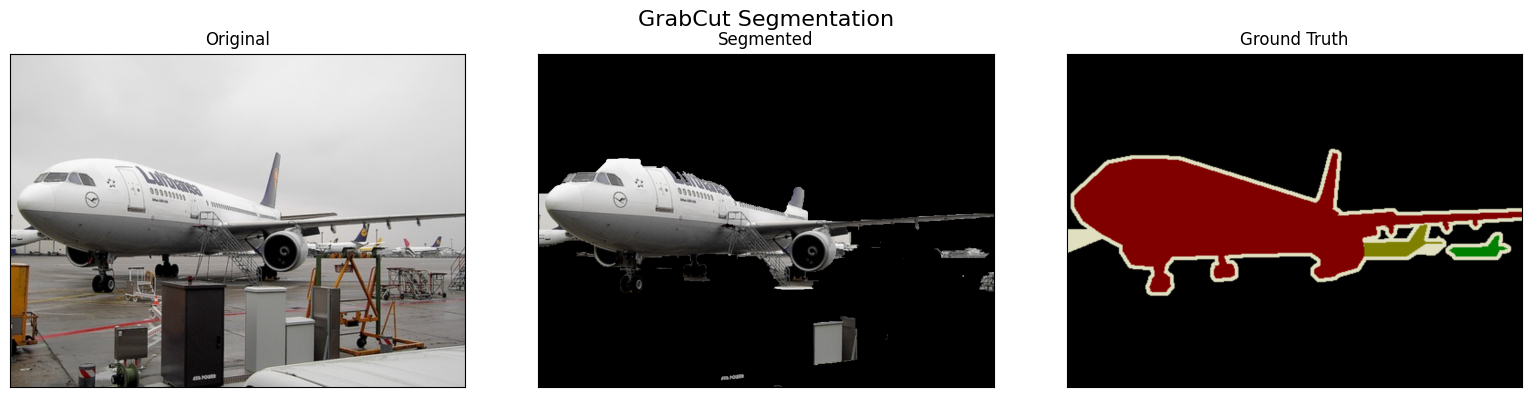

Dice score: 0.425


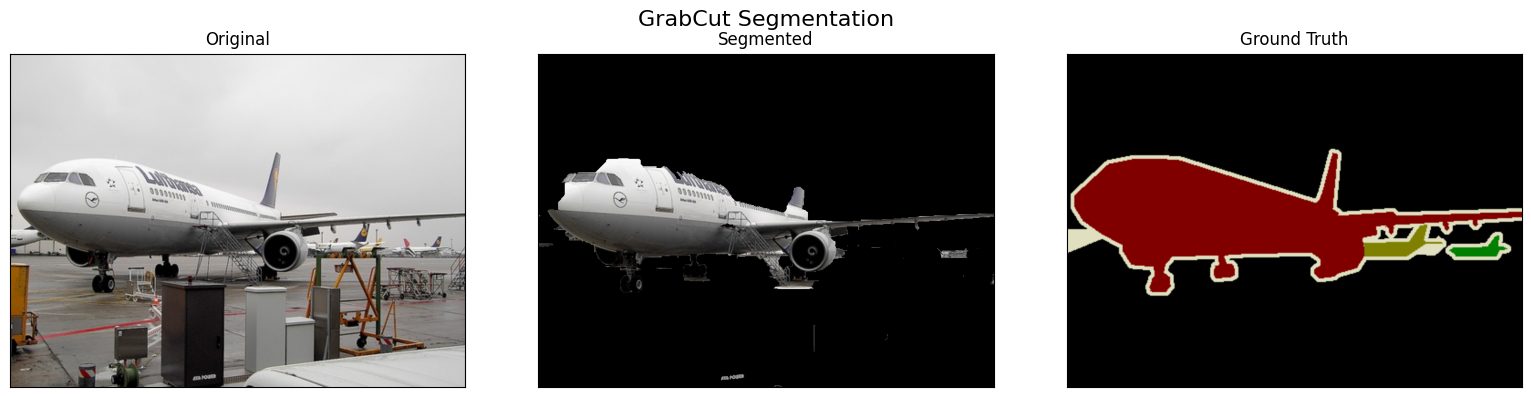

Dice score: 0.408


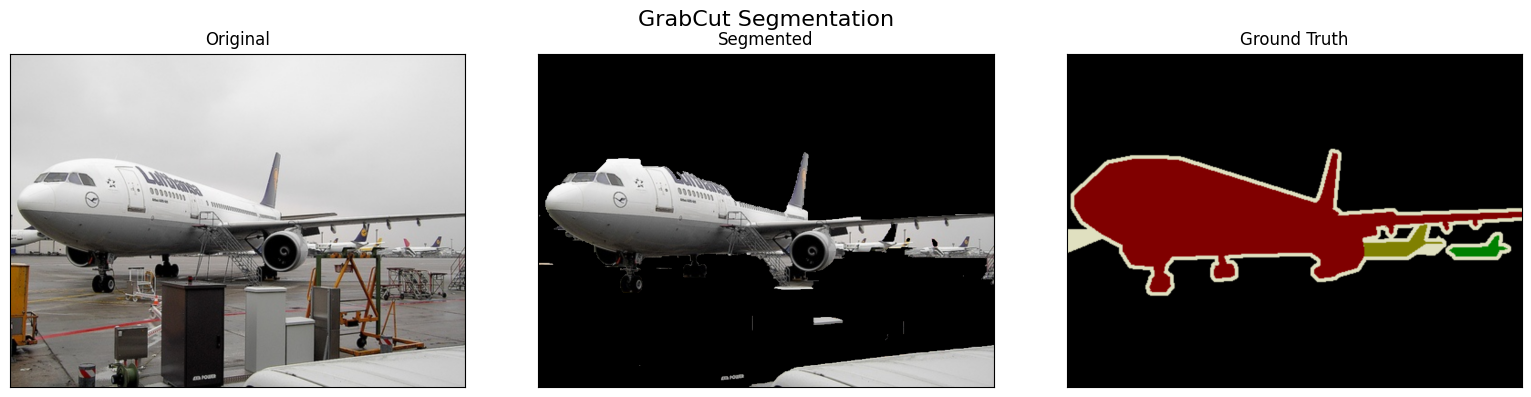

Dice score: 0.414


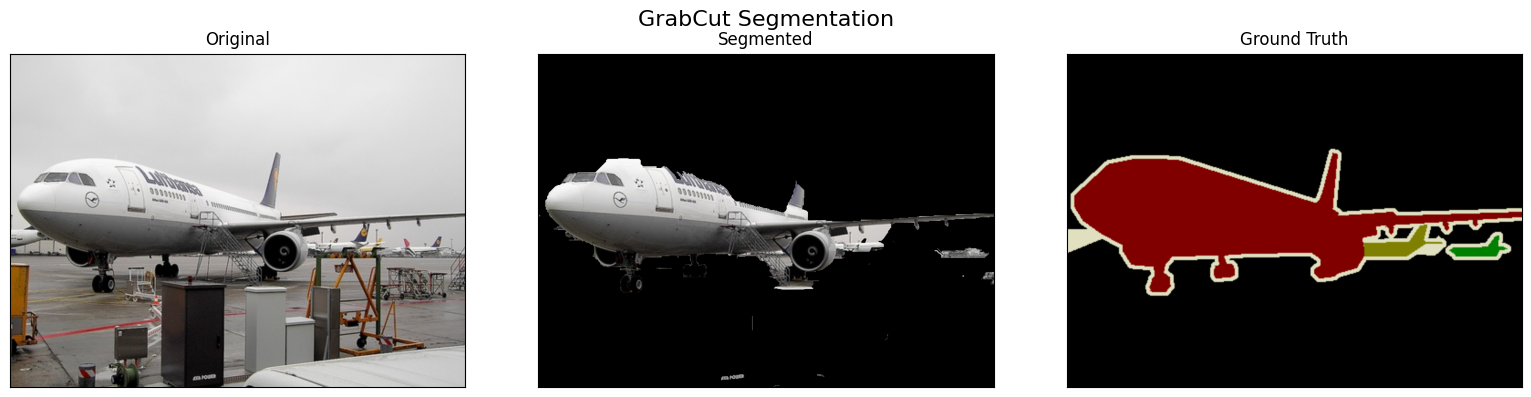

Dice score: 0.442


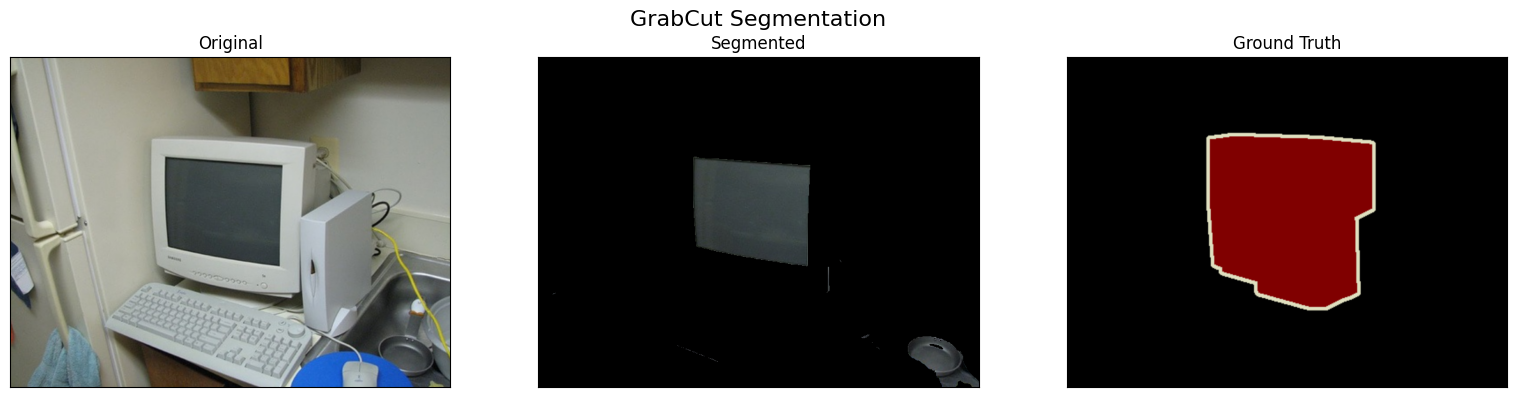

Dice score: 0.313


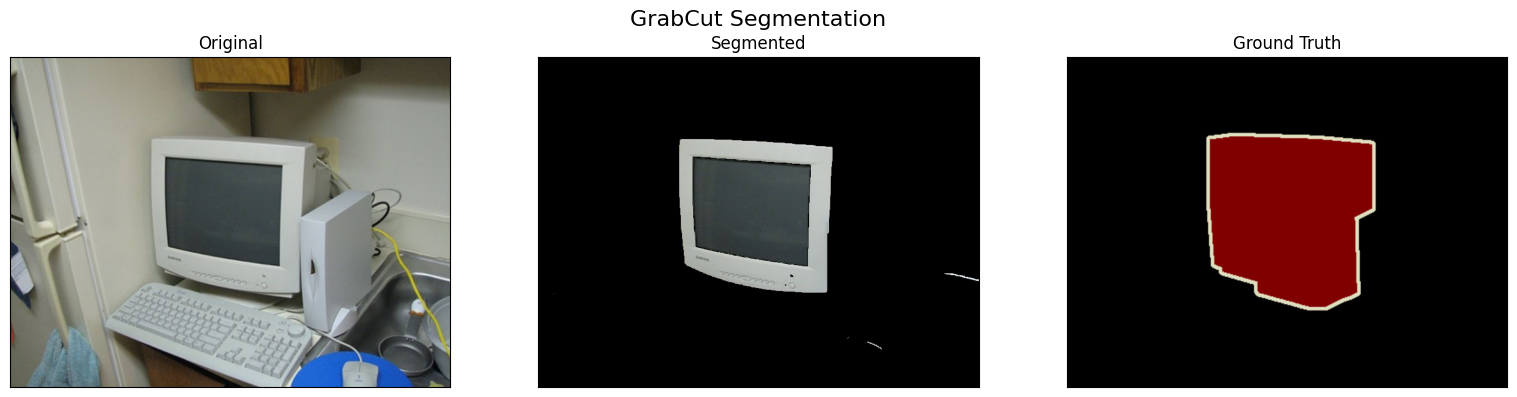

Dice score: 0.457


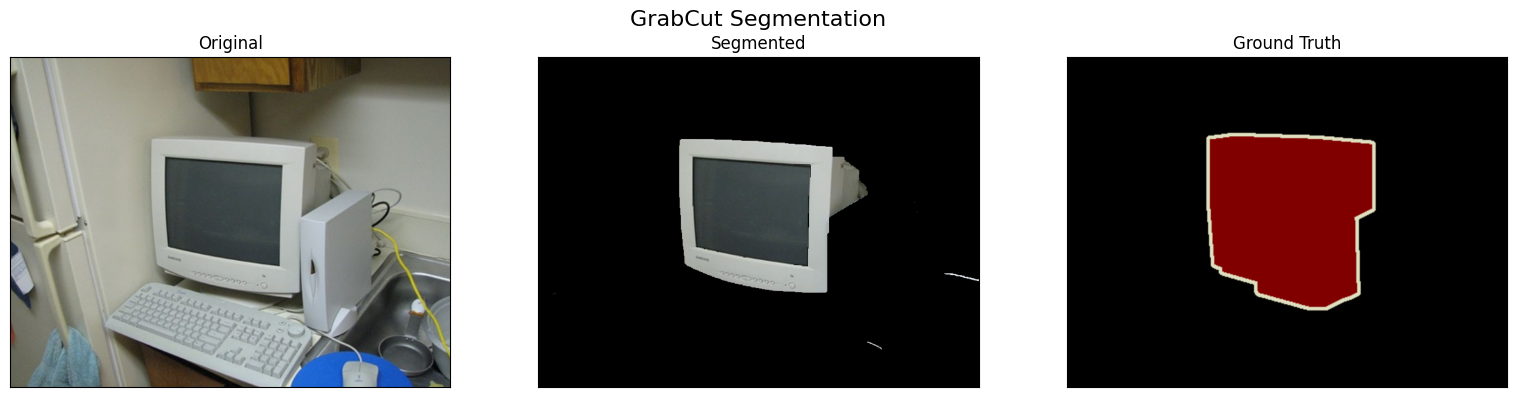

Dice score: 0.466


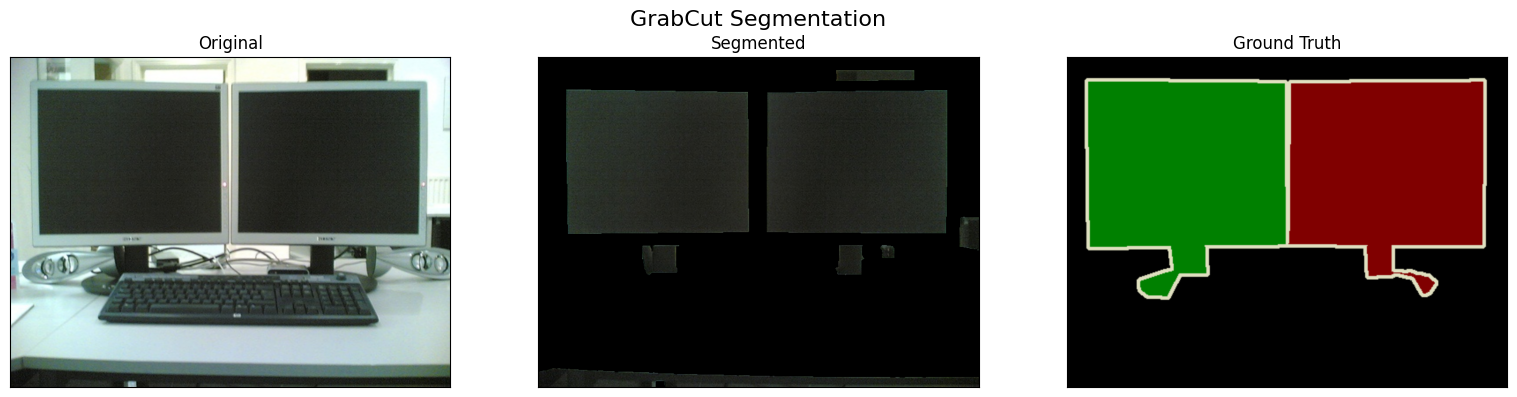

Dice score: 0.402


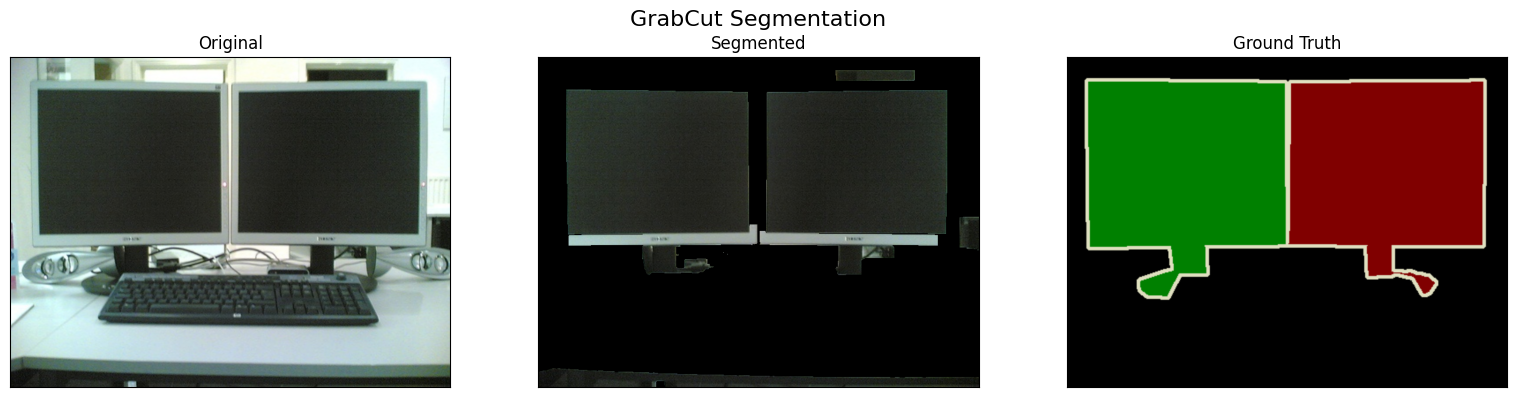

Dice score: 0.419


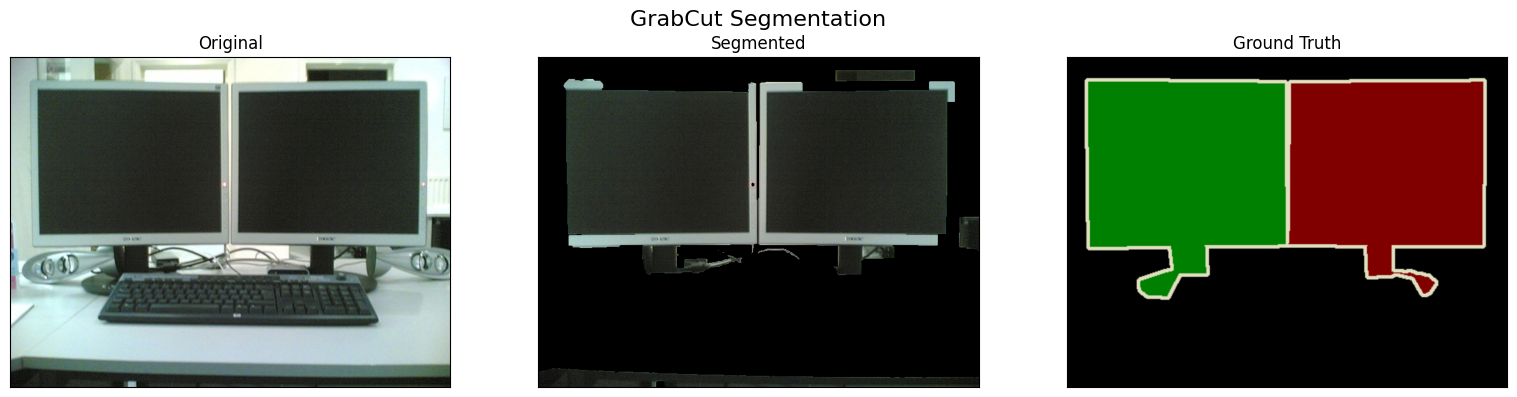

Dice score: 0.439


In [46]:
interactive_grabcut(image_files, label_files, scale=1.5)